# Twisted Bilayer Graphene

## Introduction

Twisted bilayer graphene has garnered a lot of attention in recent years due to the interesting properties it displays. When twisting the two layers of graphene at a specific twist angle, the hybridization of the two Dirac cone can lead to the formation of a flat band which can give rise to superconductivity and Mott insulator signatures. To simulate this type of moire system, one needs to build a commensurate cell for each of the twist angles one is interested in. Unlike the untwisted systems, these commensurate cells can be quite large. As a first approximation, the smaller the twist angle, the larger the moire unit cell. Only a discrete set of twist angles exist, but the larger the unit cell, the more angles become accessible.

A versatile way to describe a moire system has been introduced using 4 indices in [this reference](https://iopscience.iop.org/article/10.1088/0953-8984/24/31/314210). We remind the relevant equations here.


The commensurate moire superlattices are fully defined using four integers $i$, $j$, $i^\prime$ and $j^\prime$. Here, let us use $i$ and $j$ for graphene and $i^\prime$ and $j^\prime$ for the other graphene layer. 
The two lattice vectors of the commensurate supercell $\textbf{r}_{1}$, $\textbf{r}_{2}$ 
can be related to the lattice vectors of the bottom layer $\textbf{a}_{1}$, $\textbf{a}_{2}$ and the top layer $\textbf{a}^\prime_{1}$, $\textbf{a}^\prime_{2}$ through
$$
\begin{pmatrix}
\textbf{r}_{1} \\
\textbf{r}_{2}
\end{pmatrix}
= \textbf{M}^{\prime} \cdot
\begin{pmatrix}
\textbf{a}_{1} \\
\textbf{a}_{2}
\end{pmatrix}
= \textbf{M} \cdot
\begin{pmatrix}
\textbf{a}^{\prime}_{1} \\
\textbf{a}^{\prime}_{2} 
\end{pmatrix}
$$
where we use the transformation matrices
$$
\textbf{M} =
\begin{pmatrix}
      i      &     j        \\
    - j      &     i + j
\end{pmatrix}, 
\quad
\textbf{M}^{\prime} =
\begin{pmatrix}
     i^\prime      & j^\prime       \\
    -j^\prime     & i^\prime + j^\prime
\end{pmatrix}.
$$
Defining $a_{G_1}$ and $a_{G_2}$ as the lattice constants of the two constituent layers, we can relate the lattice mismatch ratio $\alpha$ to the four indices as
$$
\alpha = \frac{a_{G_1}}{a_{G_2}} =\sqrt{\frac{(i^\prime{}^2+j^\prime{}^2+i^{\prime}j^\prime)}{i^2+i^2+ij}}
$$
and the rotation angle $\theta$ as
$$
\cos(\theta) = \frac{1}{2 \alpha g}\left[ 2 i^\prime i + 2 j^\prime j + i^\prime j + j^\prime i \right]
$$
where $g=i^2+j^2+ij$. In this case we set $a_{G_1} = a_{G_2}$ to avoid internal strain.

Using these equations will be our first task in the next section where we will build and visualize the moire unit cell.
We then will use this moire unit cell to calculate the density of states using Lanczos recursion.






## Building the commensurate cell

Create a twisted bilayer system using the `31 30 30 31` indices and visualize the structure using the methods given below. You could also download the structure and visualize it using VMD or xCrysDen of course.

The current methods prepare structure output files that can be used as input for a LAMMPS calculation or directly as input for the GRABNES code.

A table with relevant indices is given in [this reference](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.106.115410). 

In [ ]:
!chmod -R 555 /drive/MyDrive/Twistronics2023/tBG/

started
Angle:     3.000000000
Delta:     0.000000000

                a     b     a'    b'       Delta            Angle       N   #1   #2
For angle:      90    53    84    60     0.000541980     2.999897191   43 15679 15696
For delta:      23    21    21    23     0.000000000     3.006558436    4  1453  1453
For both:        0     0     0     0             NaN             NaN    0     0     0

Final angle:     3.006558
Final BN lattice parameter:     2.460190
Atoms for graphene:    2906
Atoms for BN:    2906

Size of layer 1:   1 x 1453   (21 x 23)
Size of layer 2:   1 x 1453   (23 x 21)
 lambda1:   46.889052871787889     
 lambda2:   93.778105743575878     


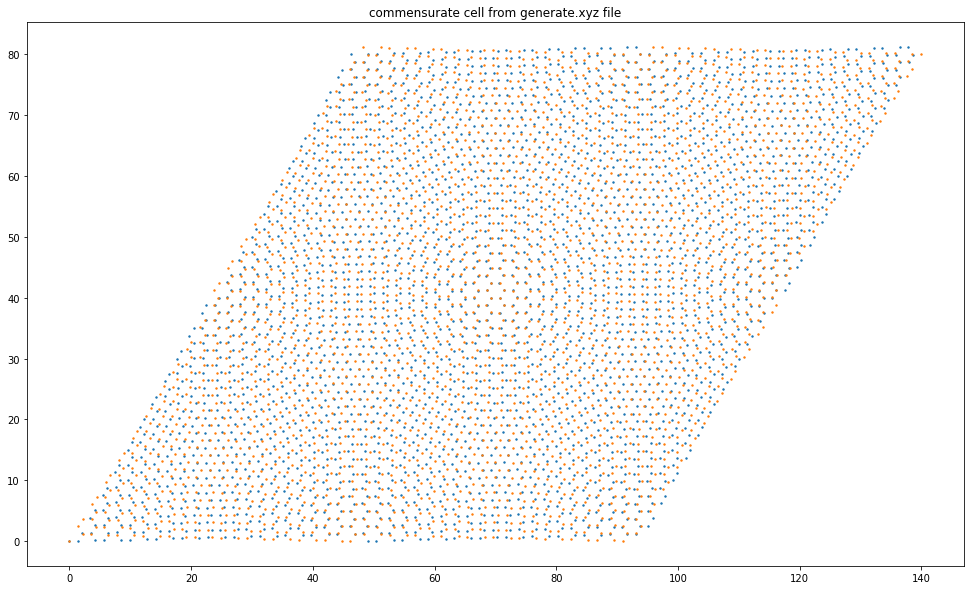

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
workingDir = rootDir + "tBG/"
os.chdir(workingDir)
#pg.prepare_tBG_commensurate_cell_input([31,30,30,31]) # Obtains the commensurate cell using integers
pg.prepare_tBG_commensurate_cell_input(3.0) # Prepares input for fortran code
!/drive/MyDrive/Twistronics2023/tBG/a.out # Runs the fortran executable
pg.prepare_tBG_commensurate_cell_xyz() # Obtains the output in different formats including lammps compatible files
plt.figure(figsize=(20,10))
pg.plotStructure("generate.xyz")
plt.gca().set_aspect("equal")


## Hamiltonian

For the tBG Hamiltonian, we use the SHE model introduced [here](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.106.115410) where the intralayer F2G2 model is the same as the one we used for single layer graphene in the previous session and the interlayer terms are given by a reparametrized and magic angle-renormalized two-center TC approximation model for which we remind the main expression here.
$$
t_{{\rm SHE}, \, ij} = 
\begin{cases} 
t^{{\rm intra}}_{{\rm F2G2}, \, ij} 
& \mbox{if }   i \in \mbox{ layer} j \\ 
S \, \exp\left[ {(c_{ij} - p)}/{q} \right] \, t^{{\rm inter}}_{{\rm TC}, \, ij} & \mbox{if }  i \notin  \mbox{ layer} j
\end{cases}
$$
where $p = 3.25$ Ang and $q = 1.34$ Ang capture the interlayer-dependence of the DFT parametrization and S is a relaxation-dependent renormalization factor which anchors the magic angle at a chosen value. 
This expression contains the [original two-center approximation model](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.86.125413) reminded  as
$$
    t_{ {\rm TC}, \, ij} = V_{pp\pi}(r_{ij}) \left[1 - \left(\frac{ c_{ij} }{r_{ij}} \right)^2 \right] + V_{pp\sigma}(r_{ij}) \left(\frac{ c_{ij} }{r_{ij}} \right)^2
$$
where
$$
    V_{pp\pi}(r_{ij}) = V_{pp\pi}^0 \exp\left(-\frac{r_{ij}-a_{\rm CC}}{r_0}\right)
$$
and
$$
    V_{pp\sigma}(r_{ij}) = V_{pp\sigma}^0 \exp\left(-\frac{r_{ij}-c_0}{r_0}\right),
$$
where $r_{ij} = \left| \textbf{r}_{ij} \right|$ is the magnitude of the interatomic distance 
and $c_{ij} = \textbf{r}_{ij} \cdot \textbf{e}_z$ is the vertical axis projection along the 
$z$-axis normal to the graphene plane. 
For simplicity, here we have defined a fixed normal vector $\textbf{e}_z$ along the $z$-axis 
rather than allowing it to tilt with the local curvature following the surface corrugation. 
The parameter $c_0 = 3.35$ Ang is the interlayer distance, 
$a_\text{CC} = 1.42$ Ang is the rigid graphene's interatomic carbon distance, 
$V_{pp\pi}^0 = -2.7$ eV the transfer integral between nearest-neighbor atoms, 
$V_{pp\sigma}^0 = 0.48$ eV the transfer integral between two vertically aligned atoms
that were fitted to generalized gradient approximation (GGA) data for fixed interlayer distances. The decay length of the transfer integral is chosen as $r_0 = 0.184 a$ such that the next-nearest intralayer coupling becomes 0.1 $V_{pp\sigma}^0$. 
%
The cutoff for this distance-dependent model is finally set to $4.9$ Ang beyond which 
additional contributions do not affect the observables anymore.


## Density of States

### Lanczos DOS

Calculate the Lanczos DOS and optimize the supercell size to get smooth behavior of the curve. Note for the current TB model we have to include a relatively large number of neighbors. bBecause of this, the memory requirements can become quite large. For the sake of this session using Google Colab resources, consider small cells up to `SuperCell 10` for $1.08^\circ$ twist angle. 

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "tBG/"
#os.mkdir(workingDir)
workingDir = rootDir + "tBG/bandstructure/"
#os.mkdir(workingDir)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem TwistedBilayerBasedOnMoireCell", # To build graphene using the built-in grabnes methods
                       "Supercell 10", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                      # "CellSize 1",
                     "MoireCellParameters 31 30 30 31" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                 #    "MoireCellParameters 11 10 10 11" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .true.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .true.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .false.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .false.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 100",
                      "TB.NeighLevels 5",
                      "Neigh.LayerDistFactor 4.2",
                      #"nonBulkSmall .true.",
                      #"Bulk .false."
                      ]

inputStrings_diag = ["Bands.NumPoints 10",
                     "&begin Bands.Path 4",
                     " 1/3   0.0-1/3 0.0", # Gamma
                     "0.0   0.0  0.0", # M
                     "0.5   0.0 0.0", # K
                     "1/3   0.0-1/3 0.0", # Gamma
                     "&end Bands.Path"
                     ]

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.5",
                    "TypeOfBL HTC",
                    "renormalizeCoupling .true.",
                    "couplingFactor 1.008",
                  #  "couplingFactor 2.93",
                    "KoshinoSR .true.",
                    ] # Controls the first nearest neighbor hopping in the F2G2 model

inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_diag
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
#!/drive/MyDrive/lanczosKuboCode/bin/grabnes Gendata.in  #> out.log
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

(0.0, 0.05)

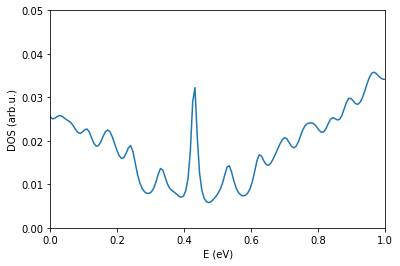

In [ ]:
os.chdir(workingDir)
fileName = "generate.DOS" # update with correct DOS
pg.plotDOS(fileName) # testing the meth
plt.xlim(0,1.0)
plt.ylim(0,0.05)

## Electronic band structure

Under normal conditions, it would not be a problem to calculate the electronic bandstructure for this magic angle system. However due to memory and parallelisation limitations inherent to using Google Colab for free, we cannot do this within this session. However, because the TB model that we are using for the interlayer interactions between the two layers of this system can be renormalized using the S factor (see [this reference](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.106.115410) for details), we can obtain by construction a flat band for a larger twist angle which requires a smaller commensurate cell. We remind the formula that can be used to estimate the strength of S for a specific twist angle as

\begin{equation}
\theta_\text{eff} = S \theta_\text{ref}/S^\prime
\end{equation}

where $\theta_\text{ref}$ is the angle of the commensurate cell and $S=0.895$ for structures that are relaxed with the EXX-RPA-fitted force field and $1.008$ for rigid structures at $3.35$ Angstrom interlayer distance. Hence for a rigid system with a twist angle of about $5.08^\circ$, corresponding to indices `7 6 6 7`, we should use a value of $S^\prime = 4.74$.

In [ ]:
Sprime = 1.008*3.14/1.08
print("S' for 3.14 degree:", Sprime)

Sprime = 1.008*3.89/1.08
print("S' for 3.89 degree:", Sprime)

Sprime = 1.008*5.08/1.08
print("S' for 5.08 degree:", Sprime)

S' for 3.14 degree: 2.9306666666666663
S' for 3.89 degree: 3.6306666666666665
S' for 5.08 degree: 4.7413333333333325


### Flat band

Calculate the electronic bandstructure and visualize the flat band.

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "tBG/"
#os.mkdir(workingDir)
workingDir = rootDir + "tBG/bandstructure/"
#os.mkdir(workingDir)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem TwistedBilayerBasedOnMoireCell", # To build graphene using the built-in grabnes methods
                       "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 1",
                     "MoireCellParameters 7 6 6 7" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                 #    "MoireCellParameters 11 10 10 11" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .true.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .true.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 100",
                      "TB.NeighLevels 5",
                      "Neigh.LayerDistFactor 4.2",
                      "nonBulkSmall .true.",
                      "Bulk .false."]

inputStrings_diag = ["Bands.NumPoints 10",
                     "&begin Bands.Path 4",
                     " 1/3   0.0-1/3 0.0", # Gamma
                     "0.0   0.0  0.0", # M
                     "0.5   0.0 0.0", # K
                     "1/3   0.0-1/3 0.0", # Gamma
                     "&end Bands.Path"
                     ]

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03",
                    "TypeOfBL HTC",
                    "renormalizeCoupling .true.",
                    "couplingFactor 4.7037037", # S'/S
                  #  "couplingFactor 2.93",
                    "KoshinoSR .true.",
                    ] # Controls the first nearest neighbor hopping in the F2G2 model

inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_diag
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
#!/drive/MyDrive/lanczosKuboCode/bin/grabnes Gendata.in  > out.log
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

<_io.TextIOWrapper name='/drive/MyDrive/Twistronics2023/tBG/bandstructure//generate.bands.dat' mode='r' encoding='UTF-8'>
508 25


(0.0, 1.5)

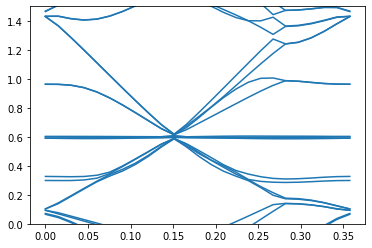

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
os.chdir(workingDir)
pg.transformBands("generate.bands")
pg.plot_electronic_bandstructure(workingDir, 2, 0.2)
#plt.ylim(0.4,0.7)
plt.ylim(0,1.5)
#plt.axvline(0.491544*3)
#plt.axvline(0.775337*3

If you correctly ran the calculation, you should see a flat band occuring in this $5.08^\circ$ simulation cell when increasing the coupling strength using the formula we showed earlier. Please note that we used this formula for illustration purposes so that we can still illustrate flat bands on the single core system that Google Colab provides us with. The larger the difference between the effective angle and the reference angle, the less accurate this approach will become, especially for relaxed systems where the relaxation strength is angle-dependent. Under normal conditions, you would be calculating it for reference angles that are very close to the effective angles. This is realisticably doable on most modern computer clusters in less than 15 minutes in the case of first magic angle of tBG.